# HeathCare Managemant EDA Task
### The following steps are followed to complete the task 

#### Step 1: Prepare Data for Analysis

In [1]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load data
df = pd.read_csv('diabetic_data.csv')
df.replace('?', np.nan, inplace=True)

### 1. Descriptive statistical analysis for numerical features

In [5]:
# Select the numerical features
numerical_features = ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 
                      'num_medications', 'number_outpatient', 'number_emergency', 
                      'number_inpatient', 'number_diagnoses']

# Generate and display the statistics
desc_stats = df[numerical_features].describe()
print(desc_stats)

       time_in_hospital  num_lab_procedures  num_procedures  num_medications  \
count     101766.000000       101766.000000   101766.000000    101766.000000   
mean           4.395987           43.095641        1.339730        16.021844   
std            2.985108           19.674362        1.705807         8.127566   
min            1.000000            1.000000        0.000000         1.000000   
25%            2.000000           31.000000        0.000000        10.000000   
50%            4.000000           44.000000        1.000000        15.000000   
75%            6.000000           57.000000        2.000000        20.000000   
max           14.000000          132.000000        6.000000        81.000000   

       number_outpatient  number_emergency  number_inpatient  number_diagnoses  
count      101766.000000     101766.000000     101766.000000     101766.000000  
mean            0.369357          0.197836          0.635566          7.422607  
std             1.267265          0.

### 2. Distribution of categorical features - race and gender

C:\Users\KIIT0001\AppData\Local\Temp\ipykernel_27772\3297752436.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='race', palette='viridis')


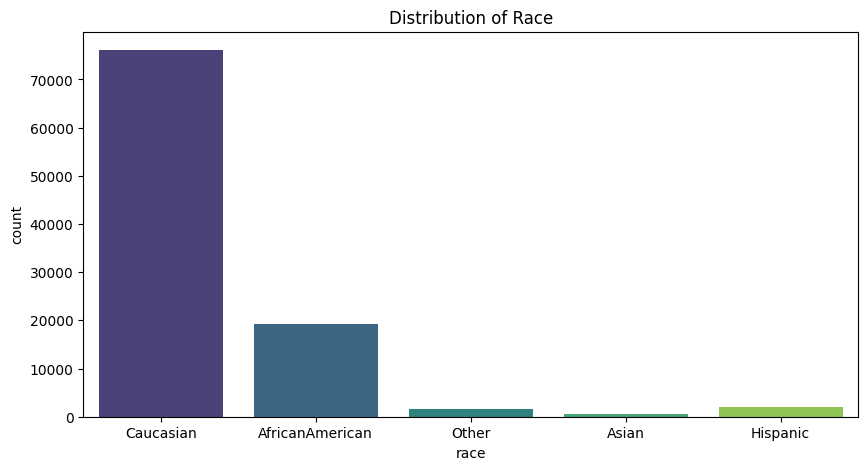

C:\Users\KIIT0001\AppData\Local\Temp\ipykernel_27772\3297752436.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='gender', palette='Set2')


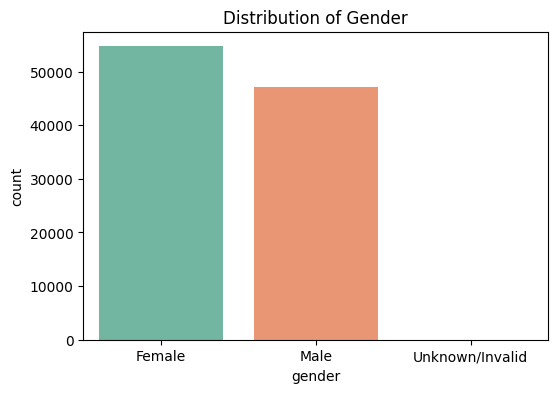

In [10]:
# Based on Race
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='race', palette='viridis')
plt.title('Distribution of Race')
plt.show()

# Based on Gender 
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='gender', palette='Set2')
plt.title('Distribution of Gender')
plt.show()

### 3. Relationship between readmission status and age

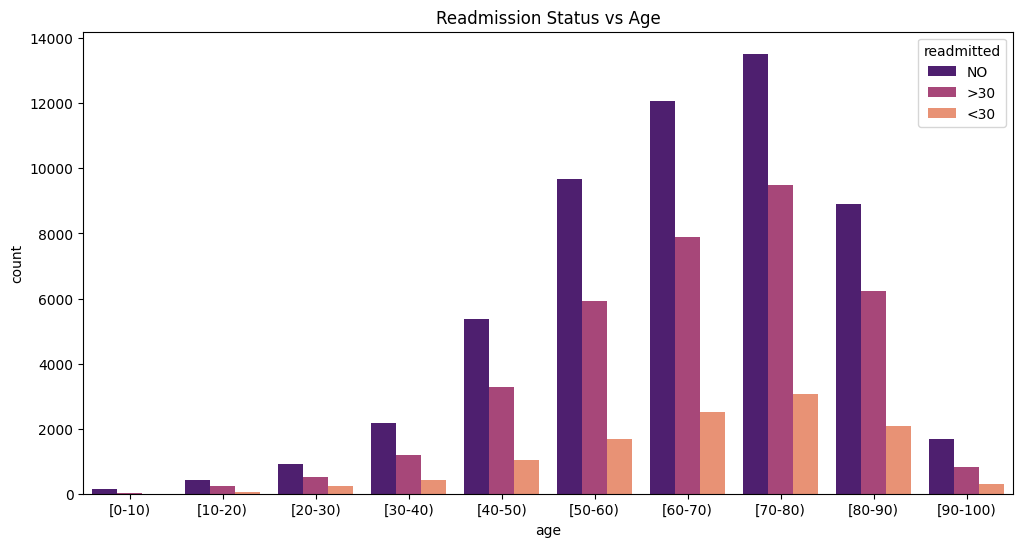

In [11]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='age', hue='readmitted', palette='magma', order=sorted(df['age'].unique()))
plt.title('Readmission Status vs Age')
plt.show()

### 4. Correlations between numerical features

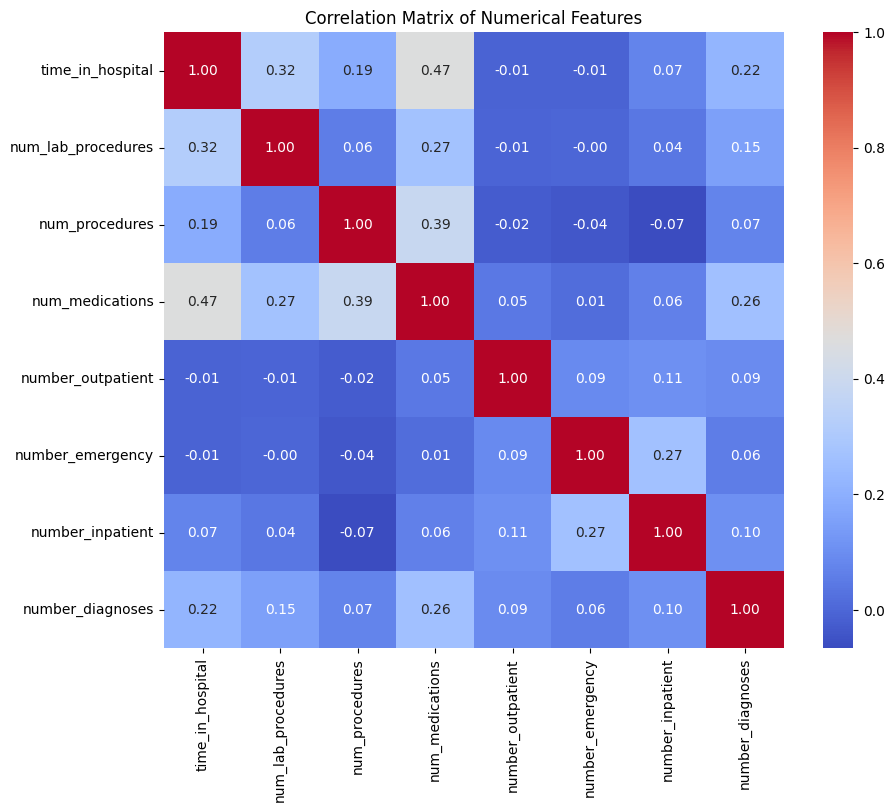

In [12]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[numerical_features].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

### 5. Distribution of medication changes and total medications taken

C:\Users\KIIT0001\AppData\Local\Temp\ipykernel_27772\410129341.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='change', palette='pastel')


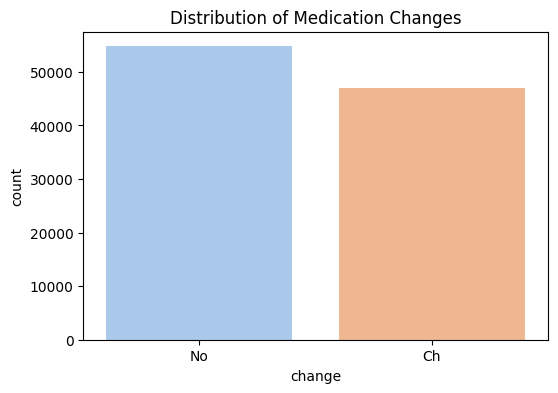

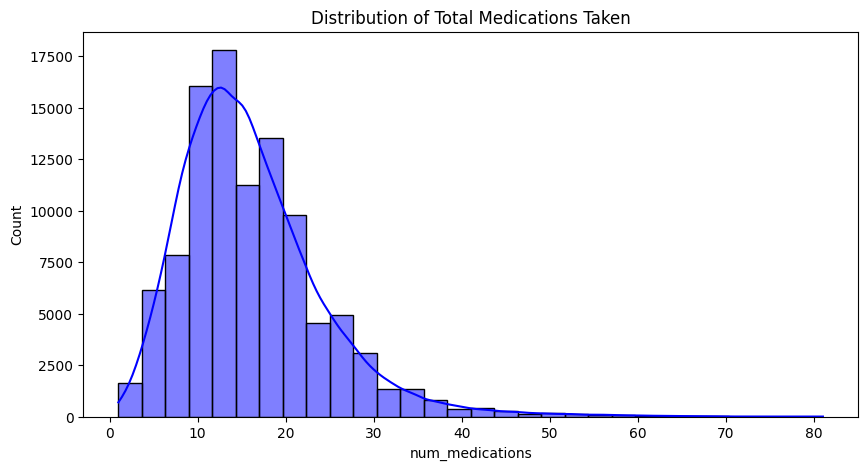

In [13]:
# Distrubution of Medication change
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='change', palette='pastel')
plt.title('Distribution of Medication Changes')
plt.show()

# Distrubution of Total Medications Taken
plt.figure(figsize=(10, 5))
sns.histplot(df['num_medications'], bins=30, kde=True, color='blue')
plt.title('Distribution of Total Medications Taken')
plt.show()

### 6. Distribution of diagnoses categories

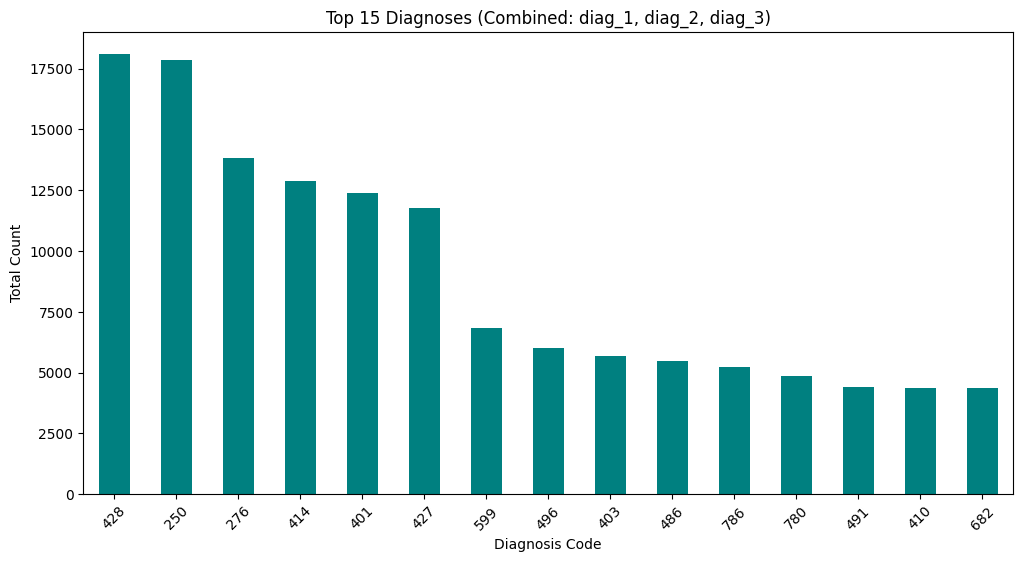

In [15]:
# Combine diag_1, diag_2, and diag_3 into one series
combined_diagnoses = pd.concat([df['diag_1'], df['diag_2'], df['diag_3']])

# Remove '?' and null values
combined_diagnoses = combined_diagnoses[combined_diagnoses != '?'].dropna()

# Plotting the top 15
plt.figure(figsize=(12, 6))
combined_diagnoses.value_counts().head(15).plot(kind='bar', color='teal')
plt.title('Top 15 Diagnoses (Combined: diag_1, diag_2, diag_3)')
plt.xlabel('Diagnosis Code')
plt.ylabel('Total Count')
plt.xticks(rotation=45)
plt.show()

### 7. Distribution across admission types, sources, and discharge dispositions

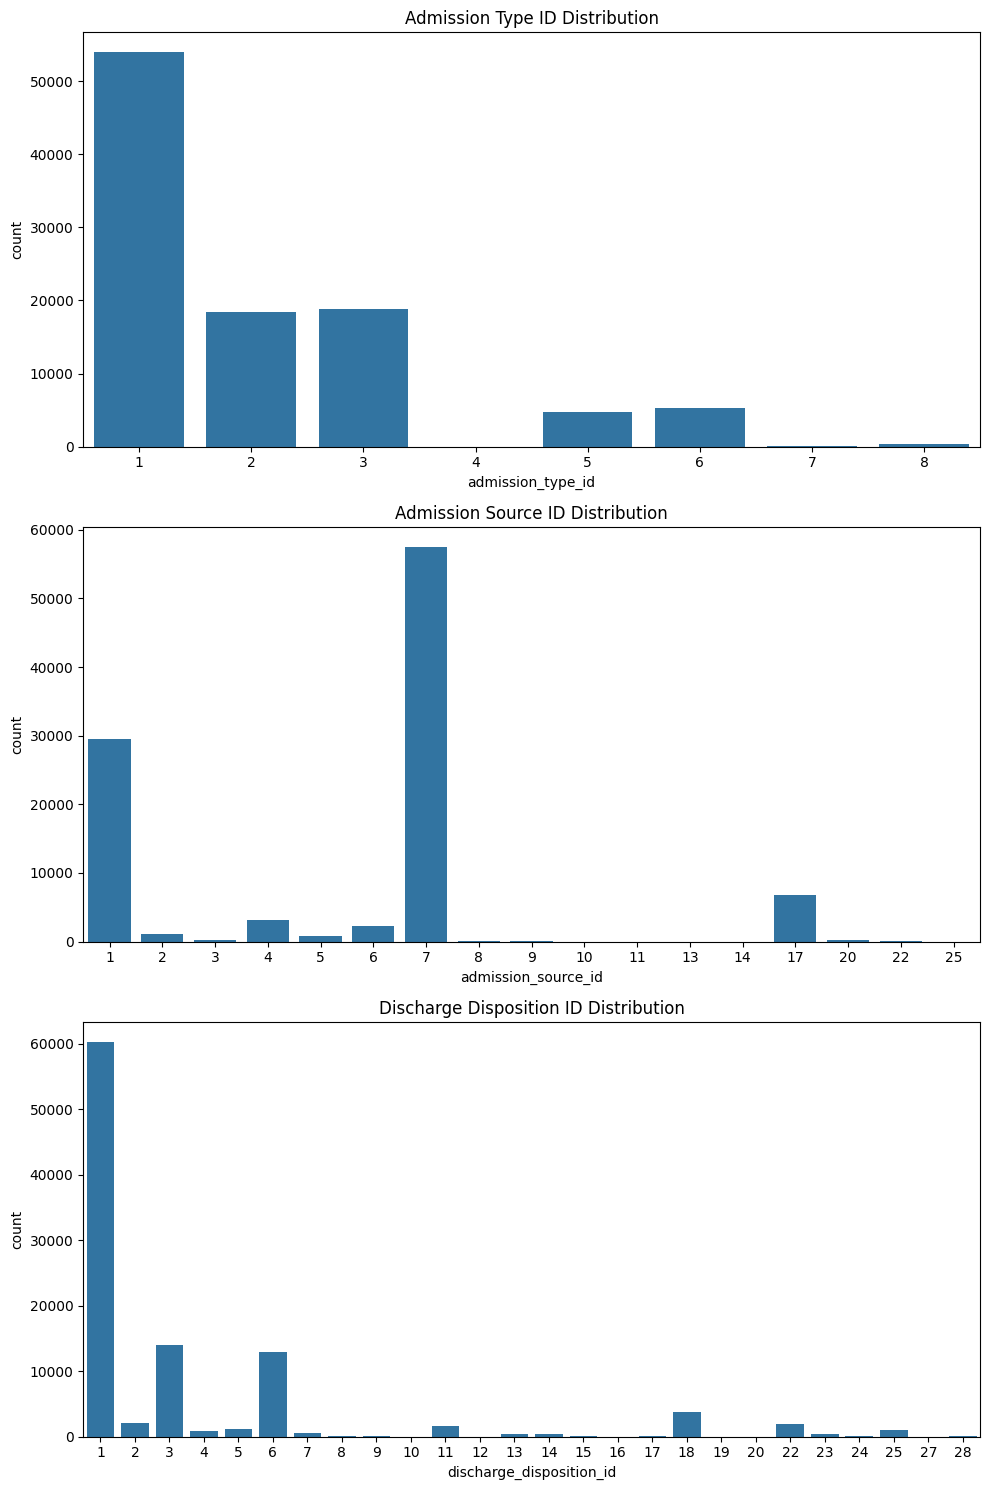

In [16]:
# Admission Type ID Distribution
fig, axes = plt.subplots(3, 1, figsize=(10, 15))
sns.countplot(data=df, x='admission_type_id', ax=axes[0])
axes[0].set_title('Admission Type ID Distribution')

# Admission Source ID Distribution
sns.countplot(data=df, x='admission_source_id', ax=axes[1])
axes[1].set_title('Admission Source ID Distribution')

# Discharge Disposition ID Distribution
sns.countplot(data=df, x='discharge_disposition_id', ax=axes[2])
axes[2].set_title('Discharge Disposition ID Distribution')

plt.tight_layout()
plt.show()

### 8. To identify and visualize the outliers in numerical features

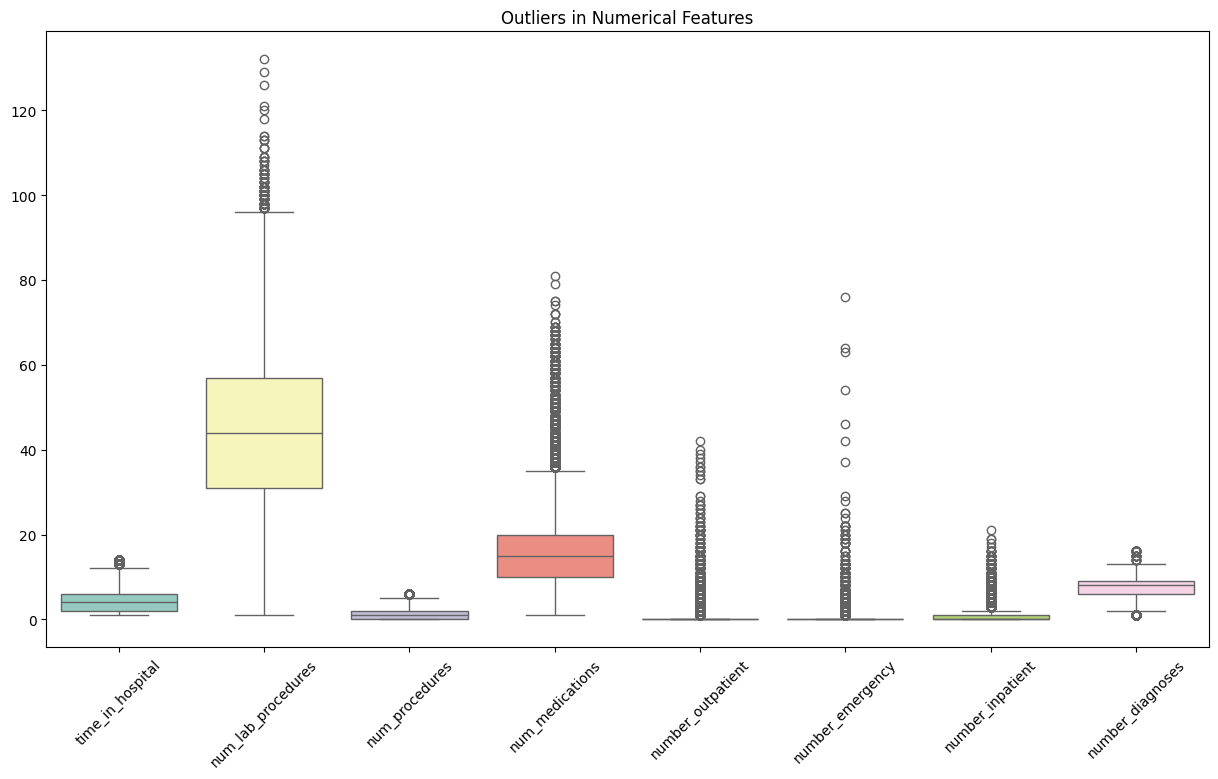

In [17]:
plt.figure(figsize=(15, 8))
sns.boxplot(data=df[numerical_features], palette='Set3')
plt.xticks(rotation=45)
plt.title('Outliers in Numerical Features')
plt.show()